2026.10.28 一致性修订：请 Restart Kernel & Run All。初始化会验证当前 embedding→特征→预测→概率；旧 niche 缓存不再复用，旧图输出已清空。Deployment 最佳模型用法保持不变。


# HCC external validation — pan-cancer Hist2Pheno (UNI2 A2)

UNI2 A2 uses a 14 px crop (7 µm after rescale to 0.5 µm/px). Run `demo_uni2.sh`. UNI predictions stay in `pred_pancancer_section`.


Seven HE JPEGs (`P1_N`, `P1_T`, `P2_N`, `P3_T`, `P5_N`, `P5_T`, `P7_T`), StarDist nuclei, **no cell-type ground truth** and no 10x JSON.
Predictions are the pan-cancer **cross-section** checkpoint
`A2_adjacent_spatial_k8mean` (L1 / L12 / L2), spatial k=8.

The JPEGs have **no OME PhysicalSize**. 96 dpi is a Windows Photo Viewer placeholder.
The finished run used **`MPP_UM = 0.5`** (`HCC.log`). At that value a native 16 px crop is already **8 µm**, so `scale_image` is false.
This notebook uses 0.5 unless the kernel was started with a different `MPP_UM`.

```bash
cd /home/lingyu/ssd2/Python/Hist2Pheno
export MPP_UM=0.5   # replace with the real scanner µm/px
bash code/External_val/HCC/demo_uni2.sh dry-run
bash code/External_val/HCC/demo_uni2.sh all
```

Outputs: `data/Visium/HCC/pred_uni2_A2_bestmlp_paired_v2_seed42/`.


In [1]:
import os
import sys
from pathlib import Path

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
# 2026.10.28, explicit checkout override / Farm 可设 HIST2PHENO_REPO
import os
if os.environ.get("HIST2PHENO_REPO"):
    REPO = Path(os.environ["HIST2PHENO_REPO"]).expanduser().resolve()
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code"))

from Hist2Pheno_pkg.external_validation import ExternalCohort, uni2_overrides

# Finished demo.sh run (code/External_val/HCC/HCC.log). Override only if you
# re-extract features with a different scanner calibration.
MPP_UM = float(os.environ.get("MPP_UM", "0.5"))

STAR_PROB_MIN = 0.0  # 2026.10.28, set above 0 to store a separate _probXX folder
import os as _prob_os
_prob_os.environ["STAR_PROB_MIN"] = "0" if float(STAR_PROB_MIN) <= 0 else f"{float(STAR_PROB_MIN):.2f}"
_prob_os.environ["UNI2_CKPT"] = str(
    REPO / "data/PanCancer/result_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42"
    / "cross_dataset_cv/A2_adjacent_spatial_k8mean/best_mlp_gpu.pt"
)
_prob_os.environ["UNI2_PRED_DIRNAME"] = "pred_uni2_A2_bestmlp_paired_v2_seed42"
_cohort = ExternalCohort(
    name="HCC",
    data_root=REPO / "data" / "Visium" / "HCC",
    repo=REPO,
    he_suffix=".jpg",
    mpp_um=MPP_UM,
    **uni2_overrides(REPO),
)
PRED_ROOT = _cohort.pred_root
composition_table = _cohort.composition_table
discover_samples = _cohort.discover_samples
geometry = _cohort.geometry
sample_paths = _cohort.sample_paths
ensure_l2_probs = _cohort.ensure_l2_probs
plot_spatial = _cohort.plot_spatial
plot_composition = _cohort.plot_composition
# Re-run the plot cell after changing these. Notebook display uses DPI; saved PNGs use SAVE_DPI.
SAVE_FIGURES = False
FIGSIZE = (17.2, 6.6)
DPI = 200
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 1.5

samples = discover_samples()
for sample in samples:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native14={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}"
    )
    p = sample_paths(sample)
    print(f"  pred exists: {p['pred'].is_file()}  {p['pred']}")

# 2026.10.28, mandatory current-input preflight / 后续直接读 h5ad 的图表也不得绕过上游
import os as _pipeline_os
_pipeline_os.environ["STAR_PROB_MIN"] = str(globals().get("STAR_PROB_MIN", 0.0))
if "ensure_l2_probs" in globals():
    _owner = ensure_l2_probs.__self__
    _current_samples = list(samples) if "samples" in globals() else _owner.discover_samples()
    _owner.cmd_predict(_current_samples, force=False, allow_cpu=True)
elif "ue" in globals():
    ue.cmd_predict(COHORT, samples, cuda_device=_pipeline_os.environ.get("CUDA_DEVICE", "0"),
                   force=False, allow_cpu=True, embedder=EMBEDDER)
else:
    raise RuntimeError("No current prediction validator; run the setup cell first")


P1_N  mpp=0.5000 µm/px  native14=7.00 µm  after rescale=7.0 µm  scale=1.0000
  pred exists: False  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_uni2_A2_bestmlp_paired_v2_seed42/P1_N/P1_N_stardist_pred.h5ad
P1_T  mpp=0.5000 µm/px  native14=7.00 µm  after rescale=7.0 µm  scale=1.0000
  pred exists: False  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_uni2_A2_bestmlp_paired_v2_seed42/P1_T/P1_T_stardist_pred.h5ad
P2_N  mpp=0.5000 µm/px  native14=7.00 µm  after rescale=7.0 µm  scale=1.0000
  pred exists: False  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_uni2_A2_bestmlp_paired_v2_seed42/P2_N/P2_N_stardist_pred.h5ad
P3_T  mpp=0.5000 µm/px  native14=7.00 µm  after rescale=7.0 µm  scale=1.0000
  pred exists: False  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_uni2_A2_bestmlp_paired_v2_seed42/P3_T/P3_T_stardist_pred.h5ad
P5_N  mpp=0.5000 µm/px  native14=7.00 µm  after rescale=7.0 µm  scale=1.0000
  pred exists: False  /home/lingyu/ssd2/Python/Hist

In [2]:
import pandas as pd
from IPython.display import Image, display

missing = [s for s in samples if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        "No predictions yet for "
        + ", ".join(missing)
        + ". Run: MPP_UM=... bash code/External_val/HCC/demo_uni2.sh all"
    )

comp = composition_table(samples)

for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {head} =====")
    display(wide.round(3))



===== L1 =====


fraction                                           mean_conf  \
sample          P1_N   P1_T   P2_N   P3_T   P5_N   P5_T   P7_T      P1_N   
class                                                                      
Endothelial    0.863  0.341  0.420  0.281  0.618  0.604  0.463     0.578   
Epithelial     0.122  0.630  0.495  0.675  0.207  0.256  0.519     0.582   
Immune         0.007  0.016  0.076  0.040  0.171  0.104  0.012     0.411   
Stromal        0.008  0.012  0.009  0.005  0.004  0.035  0.006     0.400   
Neural           NaN  0.000  0.000    NaN  0.000  0.000  0.000       NaN   

                           ...                              n            \
sample        P1_T   P2_N  ...   P5_N   P5_T   P7_T      P1_N      P1_T   
class                      ...                                            
Endothelial  0.532  0.528  ...  0.471  0.440  0.553  115827.0   60377.0   
Epithelial   0.711  0.686  ...  0.533  0.498  0.725   16338.0  111381.0   
Immune       0.441  0.488  ...  0.442  0.373  0.427     891.0    2833.0   
Stromal      0.409  0.396  ...  0.348  0.345  0.389    1102.0    2196.0   
Neural       0.503  0.532  ...  0.513  0.459  0.421       NaN      44.0   

                                                              
sample           P2_N      P3_T      P5_N     P5_T      P7_T  
class                                                         
Endothelial  106094.0   49936.0  110350.0  99091.0  119303.0  
Epithelial   124998.0  119930.0   36980.0  42067.0  133890.0  
Immune        19263.0    7049.0   30482.0  17095.0    3044.0  
Stromal        2236.0     872.0     738.0   5825.0    1573.0  
Neural           14.0       NaN       8.0     18.0      12.0  

[5 rows x 21 columns]


===== L12 =====


fraction                                           mean_conf  \
sample          P1_N   P1_T   P2_N   P3_T   P5_N   P5_T   P7_T      P1_N   
class                                                                      
Epithelial     0.209  0.403  0.312  0.390  0.172  0.168  0.524     0.515   
Myeloid        0.072  0.217  0.372  0.330  0.422  0.524  0.085     0.344   
Endothelial    0.435  0.151  0.156  0.102  0.137  0.070  0.232     0.369   
Stromal        0.270  0.093  0.104  0.073  0.075  0.218  0.123     0.321   
T_cell         0.012  0.007  0.035  0.016  0.193  0.017  0.017     0.292   
Tumor          0.002  0.128  0.022  0.088  0.001  0.002  0.018     0.535   
B_Plasma       0.001  0.001  0.000  0.000  0.001  0.001  0.001     0.254   

                           ...                             n           \
sample        P1_T   P2_N  ...   P5_N   P5_T   P7_T     P1_N     P1_T   
class                      ...                                          
Epithelial   0.567  0.569  ...  0.428  0.435  0.648  28006.0  71273.0   
Myeloid      0.397  0.448  ...  0.341  0.348  0.370   9611.0  38419.0   
Endothelial  0.375  0.360  ...  0.306  0.295  0.369  58383.0  26680.0   
Stromal      0.337  0.327  ...  0.270  0.293  0.316  36210.0  16407.0   
T_cell       0.315  0.373  ...  0.341  0.289  0.316   1564.0   1302.0   
Tumor        0.561  0.501  ...  0.457  0.475  0.515    270.0  22622.0   
B_Plasma     0.266  0.243  ...  0.240  0.233  0.253    114.0    128.0   

                                                           
sample          P2_N     P3_T     P5_N     P5_T      P7_T  
class                                                      
Epithelial   78687.0  69251.0  30625.0  27531.0  135160.0  
Myeloid      93947.0  58666.0  75294.0  85915.0   21914.0  
Endothelial  39401.0  18121.0  24422.0  11501.0   59741.0  
Stromal      26239.0  13054.0  13317.0  35845.0   31757.0  
T_cell        8784.0   2884.0  34404.0   2867.0    4280.0  
Tumor         5460.0  15723.0    262.0    351.0    4655.0  
B_Plasma        87.0     88.0    234.0     86.0     315.0  

[7 rows x 21 columns]


===== L2 =====


fraction                                            \
sample                P1_N   P1_T   P2_N   P3_T   P5_N   P5_T   P7_T   
class                                                                  
Injury_epithelial    0.203  0.437  0.436  0.468  0.388  0.223  0.504   
Endothelial          0.362  0.229  0.220  0.166  0.297  0.286  0.248   
Myofibroblast        0.261  0.055  0.094  0.075  0.037  0.034  0.098   
Plasma               0.133  0.036  0.061  0.040  0.172  0.252  0.075   
Tumor                0.002  0.127  0.026  0.098  0.002  0.004  0.017   
Neutrophil           0.001  0.023  0.082  0.088  0.029  0.010  0.004   
DC                   0.000  0.003  0.001  0.001  0.011  0.063  0.002   
Fibroblast           0.001  0.003  0.001  0.001  0.002  0.058  0.001   
Epithelial           0.003  0.033  0.008  0.018  0.007  0.051  0.031   
Macrophage           0.007  0.044  0.050  0.037  0.011  0.009  0.011   
CD4_T                0.000  0.001  0.009  0.004  0.040  0.003  0.002   
Alveolar             0.021  0.008  0.005  0.002  0.001  0.001  0.006   
NK                   0.005  0.000  0.009  0.004  0.004  0.000  0.001   
Tregs                0.000  0.001  0.000  0.000  0.001  0.005  0.000   
B_cell               0.000  0.001  0.000  0.000    NaN  0.000  0.000   
DCIS                 0.000  0.000  0.000  0.000  0.000    NaN  0.000   
CD8_T                  NaN  0.000  0.000  0.000  0.000    NaN  0.000   
Neural                 NaN  0.000  0.000    NaN    NaN    NaN    NaN   

                  mean_conf                ...                             n  \
sample                 P1_N   P1_T   P2_N  ...   P5_N   P5_T   P7_T     P1_N   
class                                      ...                                 
Injury_epithelial     0.441  0.451  0.477  ...  0.392  0.307  0.534  27181.0   
Endothelial           0.325  0.319  0.301  ...  0.244  0.215  0.332  48591.0   
Myofibroblast         0.285  0.263  0.277  ...  0.221  0.212  0.279  35030.0   
Plasma                0.303  0.276  0.271  ...  0.243  0.230  0.291  17814.0   
Tumor                 0.407  0.450  0.400  ...  0.335  0.324  0.430    309.0   
Neutrophil            0.237  0.239  0.298  ...  0.233  0.191  0.235    201.0   
DC                    0.192  0.236  0.204  ...  0.201  0.206  0.220     15.0   
Fibroblast            0.227  0.230  0.195  ...  0.169  0.180  0.192    134.0   
Epithelial            0.450  0.387  0.355  ...  0.357  0.283  0.414    464.0   
Macrophage            0.289  0.268  0.285  ...  0.252  0.213  0.275    919.0   
CD4_T                 0.215  0.216  0.254  ...  0.234  0.194  0.229     33.0   
Alveolar              0.277  0.284  0.271  ...  0.226  0.187  0.291   2856.0   
NK                    0.241  0.218  0.247  ...  0.194  0.171  0.217    605.0   
Tregs                 0.184  0.223  0.192  ...  0.165  0.181  0.230      1.0   
B_cell                0.197  0.242  0.203  ...    NaN  0.210  0.208      3.0   
DCIS                  0.272  0.331  0.406  ...  0.198    NaN  0.277      2.0   
CD8_T                   NaN  0.257  0.219  ...  0.176    NaN  0.227      NaN   
Neural                  NaN  0.407  0.269  ...    NaN    NaN    NaN      NaN   

                                                                           
sample                P1_T      P2_N     P3_T     P5_N     P5_T      P7_T  
class                                                                      
Injury_epithelial  77247.0  110063.0  83164.0  69317.0  36548.0  129957.0  
Endothelial        40550.0   55666.0  29473.0  53032.0  46990.0   63944.0  
Myofibroblast       9689.0   23645.0  13392.0   6526.0   5565.0   25311.0  
Plasma              6379.0   15369.0   7115.0  30681.0  41364.0   19431.0  
Tumor              22454.0    6572.0  17381.0    371.0    650.0    4411.0  
Neutrophil          3993.0   20759.0  15636.0   5195.0   1674.0     959.0  
DC                   532.0     187.0    142.0   1993.0  10389.0     571.0  
Fibroblast           500.0     161.0    119.0    296.0   9598.0 

[plot] P1_N  nuclei=134,158  neighbor=12.7px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.5  rows=HE+points
[plot] P1_T  nuclei=176,831  neighbor=16.1px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.5  rows=HE+points
[plot] P2_N  nuclei=252,605  neighbor=12.7px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.5  rows=HE+points
[plot] P3_T  nuclei=177,787  neighbor=13.3px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.5  rows=HE+points
[plot] P5_N  nuclei=178,558  neighbor=19.7px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.5  rows=HE+points
[plot] P5_T  nuclei=164,096  neighbor=18.2px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.5  rows=HE+points
[plot] P7_T  nuclei=257,822  neighbor=14.6px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.5  rows=HE+points


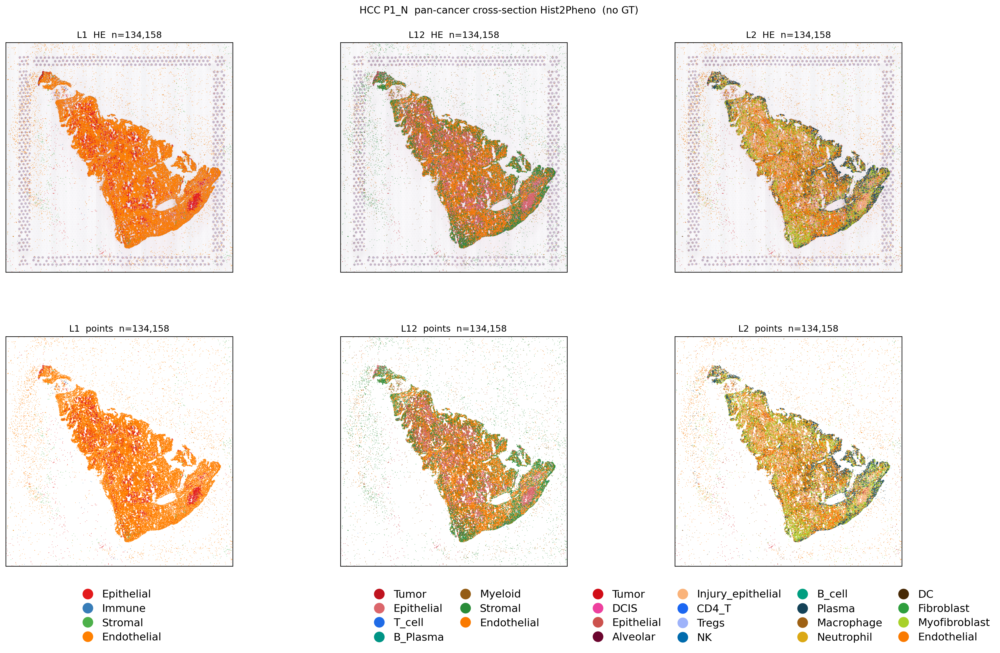

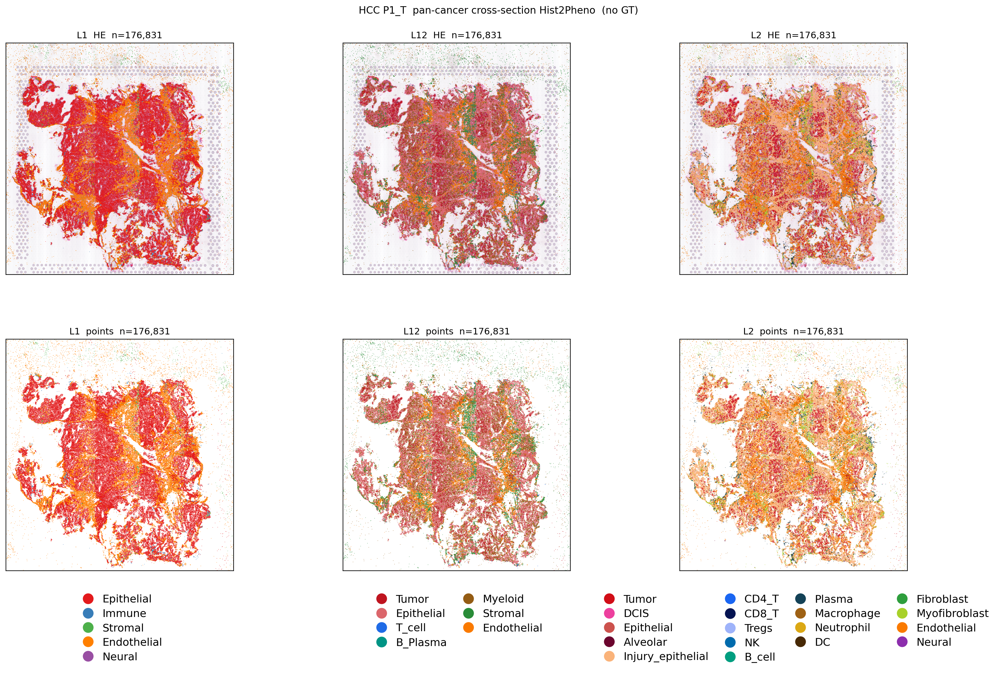

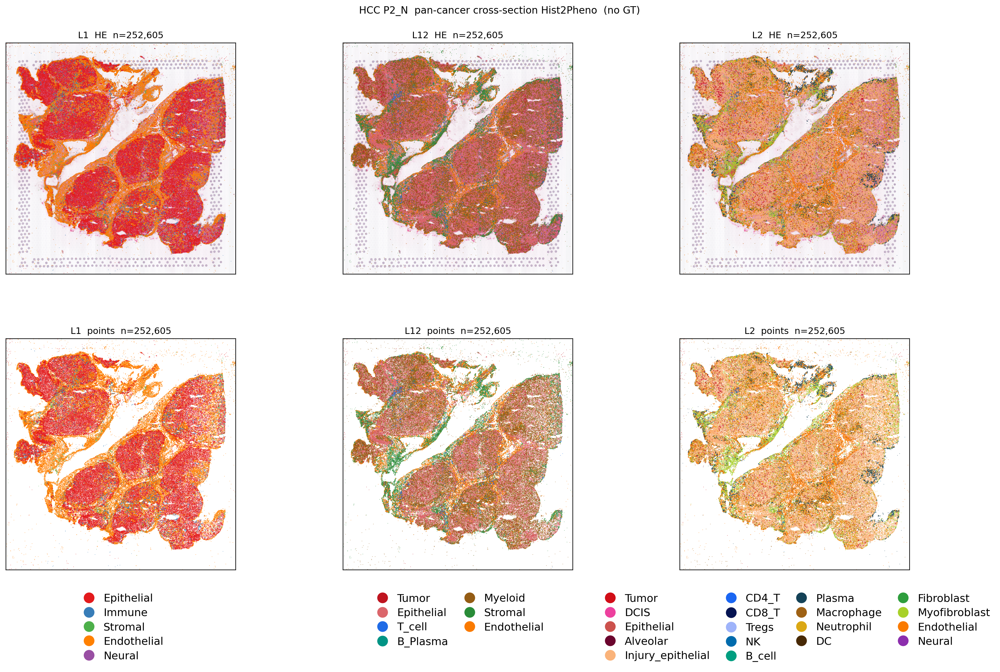

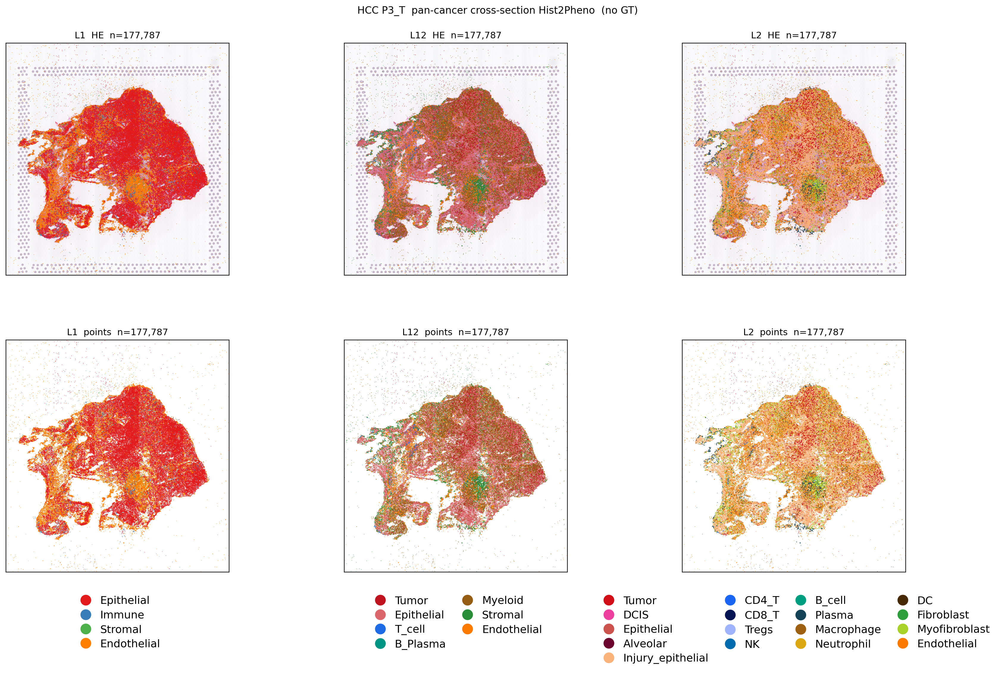

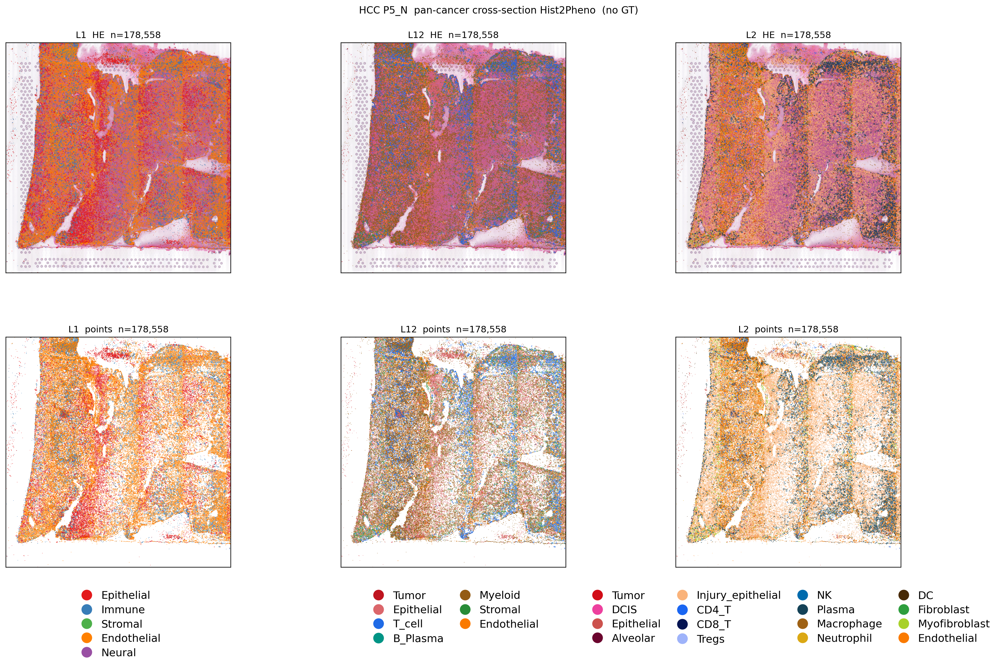

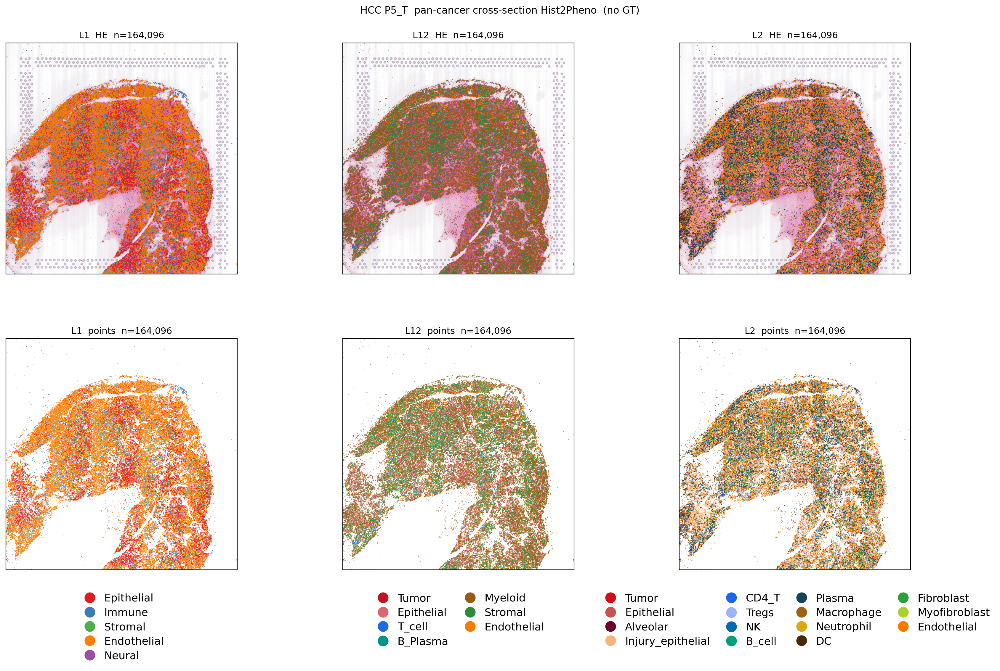

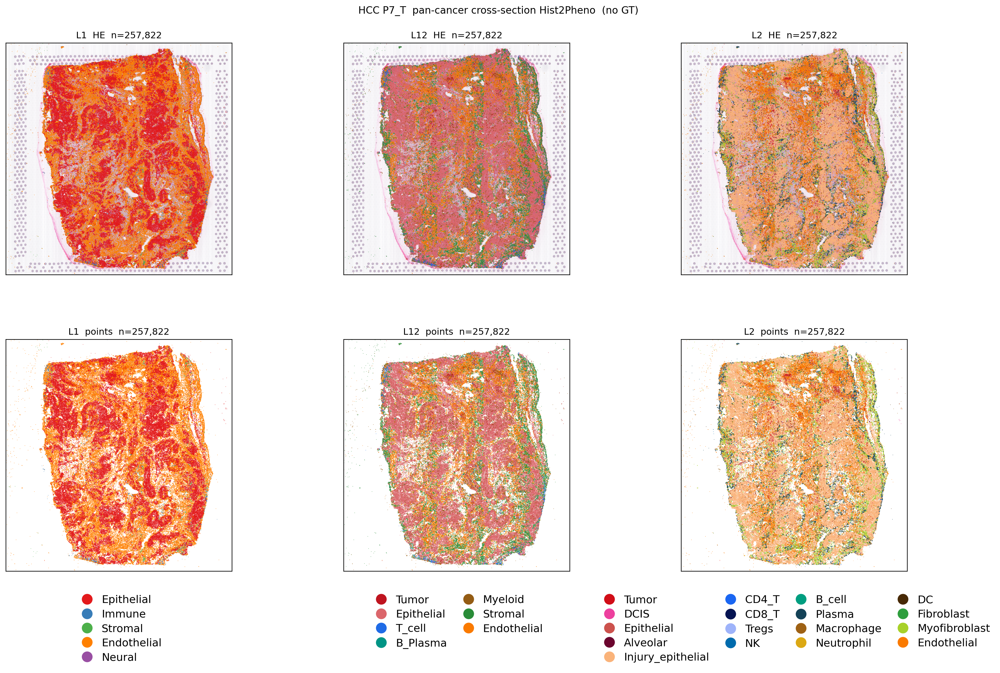

In [3]:
import matplotlib.pyplot as plt

for fig in plot_spatial(
    samples,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
):
    display(fig)
    plt.close(fig)


In [ ]:
# for fig in plot_composition(samples, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI):
#     display(fig)
#     plt.close(fig)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native JPEG pixels, so R = **55 µm** is converted with `MPP_UM`, not with 96 dpi and not with 0.5 unless that is the value you set. TLS, SRI, and TNI each use a 1×3 row: abundance, spatial score without markers, then the same spatial map with cyan candidates.


In [ ]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = True  # 2026.10.28, legacy niche cache lacks provenance; recompute from verified current probabilities

HCC_NICHE = OrganNicheConfig(
    pan_organ="pancancer_hcc",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(samples[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="HCC",
)
display(hni.index_formula_table(HCC_NICHE))


In [ ]:
import numpy as np
niche_frames = {}
for sample in samples:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        missing = hni.missing_index_cell_types(class_names, HCC_NICHE)
        if missing:
            raise RuntimeError(f"{sample} missing niche compartments: {missing}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, HCC_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, HCC_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        __import__("pipeline_provenance").publish_derived_h5ad(out,niche_path,paths["pred"], probabilities=probs, class_names=class_names, obs_names=pred.obs_names, parameters={"config":HCC_NICHE,"mpp":mpp,"radius_um":TLS_RADIUS_UM},algorithm=hni.__file__)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    niche_frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )


In [ ]:
# import matplotlib.pyplot as plt
# import pandas as pd
# from IPython.display import display

# fig_dir = PRED_ROOT / "figures"
# fig_dir.mkdir(parents=True, exist_ok=True)


# def tls_score_row(df, sample: str) -> dict:
#     a = df["idx_TLS"].to_numpy(dtype=float)
#     s = df["idx_TLS_spatial"].to_numpy(dtype=float)
#     a_hi = a >= np.percentile(a, 95)
#     s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
#     inter = int(np.logical_and(a_hi, s_hi).sum())
#     union = int(np.logical_or(a_hi, s_hi).sum())
#     n_a = int(a_hi.sum())
#     return {
#         "sample": sample,
#         "n": int(len(df)),
#         "TLS_mean": float(np.mean(a)),
#         "TLS_median": float(np.median(a)),
#         "TLS_p95": float(np.percentile(a, 95)),
#         "TLS_max": float(np.max(a)),
#         "TLS_spatial_mean": float(np.mean(s)),
#         "TLS_spatial_median": float(np.median(s)),
#         "TLS_spatial_p95": float(np.percentile(s, 95)),
#         "TLS_spatial_max": float(np.max(s)),
#         "pearson": float(np.corrcoef(a, s)[0, 1]),
#         "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
#         "top5_jaccard": (inter / union) if union else float("nan"),
#         "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
#         "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
#         "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
#     }


# quant_rows = [tls_score_row(df, sample) for sample, df in niche_frames.items()]
# tls_quant = pd.DataFrame(quant_rows)
# tls_quant_path = fig_dir / "tls_score_summary.csv"
# tls_quant.to_csv(tls_quant_path, index=False)
# print(tls_quant_path)
# display(tls_quant.round(3))

# for sample, df in niche_frames.items():
#     fig, axes = hdni.plot_tls_abundance_vs_spatial(
#         df,
#         sample,
#         radius_um=TLS_RADIUS_UM,
#         use_entropy=False,
#         split_spatial_candidates=True,
#         dpi=DPI,
#         save_dpi=SAVE_DPI,
#         point_size=0.15,
#         candidate_size=1.2,
#         save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
#     )
#     display(fig)
#     plt.close(fig)

#     for abundance_col, spatial_col, candidate_col, tag in (
#         ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
#         ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
#     ):
#         fig, axes = hdni.plot_tls_abundance_vs_spatial(
#             df,
#             sample,
#             radius_um=TLS_RADIUS_UM,
#             abundance_col=abundance_col,
#             spatial_col=spatial_col,
#             candidate_col=candidate_col,
#             score_name=tag,
#             use_entropy=False,
#             split_spatial_candidates=True,
#             dpi=DPI,
#         save_dpi=SAVE_DPI,
#         point_size=0.15,
#             candidate_size=1.2,
#             save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
#         )
#         display(fig)
#         plt.close(fig)
